# Skin lesion triage with **DermLIP ViT-B/16** (Variation of DermLIP ViT-B/16)

Frozen dermatology vision encoder, small trainable head, evaluated across four public
benchmarks under simulated low-quality-camera capture.   

**Pipeline**

`image -> camera degradation -> DermLIP encoder (frozen) -> adapter -> classifier`

**Structure of this notebook**

| Section | Purpose |
|---|---|
| 1 | Environment setup without breaking Colab's dependency stack |
| 2 | Config and benchmark registry (HAM10000, Fitzpatrick17K, PAD-UFES-20, Daffodil) |
| 3 | DermLIP ViT-B/16 loading |
| 4 | Physically-ordered camera simulator |
| 5 | Embedding extraction and caching |
| 6 | Zero-shot baseline (no training required) |
| 7 | Linear probe |
| 8 | Robustness-aware shared-adapter head |
| 9 | Evaluation across benchmarks x corruption levels |
| 10 | Validating the simulator against real device photos |
| 11 | Export and deployment notes |

**Datasets are not wired up yet.** 

---

### About the model

DermLIP is a CLIP-style vision-language model from the Derm1M work (ICCV 2025),
contrastively trained on roughly 1M dermatology image-text pairs. The `ViT-B-16`
variant initialises from OpenAI CLIP. 

Note: DermLIP and PanDerm are made by the same organization, but aren't the same

`ViT-B-16` is chosen here because PAD-UFES-20 is smartphone clinical photography, the
closest public proxy to a Raspberry Pi camera, and because its licence position is the
least encumbered of the available options.

## 1. Environment setup

Colab ships `transformers`, `accelerate`, `huggingface_hub`, `scikit-learn`, `pillow`,
`pandas`, `numpy` and `matplotlib` preinstalled at mutually compatible versions. Running
`pip install -U` across that list resolves each package to its newest release without
checking the rest of the environment, which is what produces:

```
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5
numba 0.61.2 requires numpy<2.3, but you have numpy 2.5.3
```

The `numba` one has teeth — `numpy<2.3` there is a compiled-ABI bound, so violating it
tends to produce crashes rather than clean errors.

`open_clip_torch` is the only package this notebook actually needs to add. It pulls in
`ftfy` and is satisfied by Colab's existing `torch` and `timm`.

**Run this cell first, before importing anything.**

Requirements:
pip install -q open_clip_torch, scikit_learn

In [1]:
# --- clean up orphaned directories from any interrupted previous install ---
# pip renames a package dir to ~ame while replacing it, and leaves it behind if
# the process dies mid-uninstall. Harmless, but it warns on every later pip call.
!rm -rf /usr/local/lib/python*/dist-packages/~* 2>/dev/null

# --- install ONLY what is missing; do not -U the preinstalled stack ---
!pip install -q open_clip_torch

# --- report, do not assume ---
!pip check || echo "(the 'ipython requires jedi' line is a stock Colab quirk - ignore it)"

# PIP INSTALL:
%pip install torch open_clip_torch numpy pandas pillow scikit-learn matplotlib 

# If there's any issues with the install, uninstall and try the command below. It specifies the versions of the packages:
# %pip install torch==2.14.0 open_clip_torch==3.3.0 numpy==2.5.3 pandas==3.0.6 pillow==12.3.0 scikit-learn==1.9.1 matplotlib==3.11.2

The system cannot find the path specified.
error: uv trampoline failed to canonicalize script path


"(the 'ipython requires jedi' line is a stock Colab quirk - ignore it)"


error: uv trampoline failed to canonicalize script path


Note: you may need to restart the kernel to use updated packages.


In [2]:
import PIL, torch, open_clip, numpy, pandas, sklearn, matplotlib

print(f"{'pillow':14s}", PIL.__version__)
print(f"{'torch':14s}", torch.__version__)
print(f"{'open_clip':14s}", open_clip.__version__)
print(f"{'numpy':14s}", numpy.__version__)
print(f"{'pandas':14s}", pandas.__version__)
print(f"{'scikit-learn':14s}", sklearn.__version__)
print(f"{'matplotlib':14s}", matplotlib.__version__)

print("\nCUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU. Runtime > Change runtime type > T4 GPU.")
    print("Linear probing will still work on CPU, but embedding extraction will be slow.")

c:\Users\Maxim\OneDrive\Documents\GitHub\skin-lesion-detector\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


pillow         12.3.0
torch          2.14.0+cpu
open_clip      3.3.0
numpy          2.5.3
pandas         3.0.6
scikit-learn   1.9.1
matplotlib     3.11.2

CUDA available: False
No GPU. Runtime > Change runtime type > T4 GPU.
Linear probing will still work on CPU, but embedding extraction will be slow.


If that install replaced anything already imported this session, pip will say
`You must restart the runtime`. Do it — Runtime > Restart session — then re-run the
cell above but **not** the install cell.

Note that "Restart session" keeps the same VM and disk, so installs survive.
"Disconnect and delete runtime" gets a fresh disk and loses them.

## 2. Configuration and Benchmarks

We've got 4 important benchmarks. All of these are skin lesion data. Critically, we really want to optimize PAD-UFES-20

| Benchmark | Classes | Modality | Why it is here |
|---|---|---|---|
| HAM10000 | 7 | **Dermoscopy** | Standard reference point; contact lens, polarised light |
| Fitzpatrick17K | 114 / 9 / 3 | **Clinical photo** | Spans Fitzpatrick skin types — the fairness check |
| PAD-UFES-20 | 6 | **Smartphone clinical** | Closest public proxy to a Pi camera |
| Daffodil | 5 | Mixed | Non-lesion conditions (acne, vitiligo, nail psoriasis) |

A model trained on dermoscopy and deployed on a bare Pi camera is being asked to
generalise across a modality gap, not just a quality gap. **PAD-UFES-20 is the number
to watch** unless you are fitting a dermatoscope lens to the device.

Published DermLIP ViT-B/16 linear-probe accuracy at 100% labels, for reference:
PAD `.761`, HAM `.852`, F17K `.510`, Daffodil `.964`.

### Expected CSV schema

Each benchmark wants a CSV with:

- `image_path` — relative to that benchmark's `img_dir`
- `label` — string class name, must be in the registered `classes` list
- `patient_id` *(optional but strongly recommended)* — grouping key for leak-free splits
- `fitzpatrick` *(optional)* — skin type, for subgroup analysis
- `split` *(optional)* — `train`/`val`/`test`; if absent, a grouped split is generated

Use the pre-split versions from the Derm1M and PanDerm repos if you want numbers
comparable to the papers. Both note their splits differ from the official releases
specifically to remove train/test leakage.

In [3]:
import os, io, json, math, random, warnings, hashlib
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Optional, List, Dict

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, recall_score, precision_score,
    f1_score, accuracy_score, balanced_accuracy_score, confusion_matrix,
)

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


In [4]:
@dataclass
class Config:
    model_id: str = "hf-hub:redlessone/DermLIP_ViT-B-16"
    data_root: str = "data"
    cache_dir: str = "cache_embeddings"
    output_dir: str = "outputs_dermlip"

    embed_batch_size: int = 64
    val_frac: float = 0.15
    test_frac: float = 0.15

    # head
    adapter_dim: int = 256
    proj_dim: int = 128
    dropout: float = 0.20
    batch_size: int = 128
    epochs: int = 30
    lr: float = 1e-3
    weight_decay: float = 1e-4
    contrastive_weight: float = 0.30
    contrastive_temperature: float = 0.10

    # which simulated camera to train against, and at what severities
    train_camera: str = "picam3"
    train_severities: tuple = (0.0, 0.35, 0.7)

    # evaluation corruption ladder
    eval_cameras: tuple = ("clinical_reference", "smartphone_mid", "picam3",
                           "picam2_dim", "cheap_usb")
    eval_severity: float = 1.0

    # triage view
    target_validation_sensitivity: float = 0.90

CFG = Config()
Path(CFG.output_dir).mkdir(parents=True, exist_ok=True)
Path(CFG.cache_dir).mkdir(parents=True, exist_ok=True)
print(CFG)

Config(model_id='hf-hub:redlessone/DermLIP_ViT-B-16', data_root='data', cache_dir='cache_embeddings', output_dir='outputs_dermlip', embed_batch_size=64, val_frac=0.15, test_frac=0.15, adapter_dim=256, proj_dim=128, dropout=0.2, batch_size=128, epochs=30, lr=0.001, weight_decay=0.0001, contrastive_weight=0.3, contrastive_temperature=0.1, train_camera='picam3', train_severities=(0.0, 0.35, 0.7), eval_cameras=('clinical_reference', 'smartphone_mid', 'picam3', 'picam2_dim', 'cheap_usb'), eval_severity=1.0, target_validation_sensitivity=0.9)


In [ ]:
# from transformers import AutoTokenizer, AutoModel, model

ModuleNotFoundError: No module named 'transformers'

In [ ]:
@dataclass
class BenchmarkSpec:
    key: str
    display: str
    modality: str
    classes: List[str]
    prompts: Dict[str, str]          # class -> zero-shot text prompt
    csv: str
    img_dir: str
    malignant: tuple = ()            # classes counted positive in the triage view
    notes: str = ""

    @property
    def n_classes(self):
        return len(self.classes)


def _p(*parts):
    return str(Path(CFG.data_root).joinpath(*parts))


BENCHMARKS = {

    "ham10000": BenchmarkSpec(
        key="ham10000", display="HAM10000", modality="dermoscopy",
        classes=["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"],
        prompts={
            "akiec": "a dermoscopic image of actinic keratosis or intraepithelial carcinoma",
            "bcc":   "a dermoscopic image of basal cell carcinoma",
            "bkl":   "a dermoscopic image of a benign keratosis-like lesion",
            "df":    "a dermoscopic image of dermatofibroma",
            "mel":   "a dermoscopic image of melanoma",
            "nv":    "a dermoscopic image of a melanocytic nevus",
            "vasc":  "a dermoscopic image of a vascular lesion",
        },
        csv=_p("ham10000", "labels.csv"), img_dir=_p("ham10000", "images"),
        malignant=("mel", "bcc", "akiec"),
        notes="Dermoscopy. Heavily nv-dominated (~67%) - always report balanced accuracy.",
    ),

    "pad_ufes": BenchmarkSpec(
        key="pad_ufes", display="PAD-UFES-20", modality="clinical (smartphone)",
        classes=["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"],
        prompts={
            "ACK": "a clinical photograph of actinic keratosis",
            "BCC": "a clinical photograph of basal cell carcinoma",
            "MEL": "a clinical photograph of melanoma",
            "NEV": "a clinical photograph of a melanocytic nevus",
            "SCC": "a clinical photograph of squamous cell carcinoma",
            "SEK": "a clinical photograph of seborrheic keratosis",
        },
        csv=_p("pad_ufes", "labels.csv"), img_dir=_p("pad_ufes", "images"),
        malignant=("MEL", "BCC", "SCC"),
        notes="PRIMARY TARGET. Smartphone clinical photos - closest proxy to a Pi camera.",
    ),

    "fitzpatrick17k": BenchmarkSpec(
        key="fitzpatrick17k", display="Fitzpatrick17K", modality="clinical photo",
        classes=["benign", "malignant", "non-neoplastic"],
        prompts={
            "benign":         "a clinical photograph of a benign skin lesion",
            "malignant":      "a clinical photograph of a malignant skin lesion",
            "non-neoplastic": "a clinical photograph of a non-neoplastic skin condition",
        },
        csv=_p("fitzpatrick17k", "labels.csv"), img_dir=_p("fitzpatrick17k", "images"),
        malignant=("malignant",),
        notes=("Defaults to the 3-class partition. Swap in the 9- or 114-class labels for "
               "the harder task the papers report. Carries Fitzpatrick skin type - use it."),
    ),

    "daffodil": BenchmarkSpec(
        key="daffodil", display="Daffodil", modality="mixed",
        classes=["acne", "vitiligo", "hyperpigmentation", "nail psoriasis", "sjs-ten"],
        prompts={
            "acne":              "a photograph of skin affected by acne",
            "vitiligo":          "a photograph of skin affected by vitiligo",
            "hyperpigmentation": "a photograph of skin showing hyperpigmentation",
            "nail psoriasis":    "a photograph of a nail affected by psoriasis",
            "sjs-ten":           "a photograph of Stevens-Johnson syndrome or toxic epidermal necrolysis",
        },
        csv=_p("daffodil", "labels.csv"), img_dir=_p("daffodil", "images"),
        malignant=(),
        notes="Non-lesion skin conditions. No malignant class, so no triage view.",
    ),
}

rows = []
for k, b in BENCHMARKS.items():
    ok = Path(b.csv).exists()
    rows.append({
        "benchmark": b.display, "modality": b.modality, "classes": b.n_classes,
        "status": "READY" if ok else "NOT CONFIGURED",
        "expected_csv": b.csv,
    })
registry_df = pd.DataFrame(rows)
print(registry_df.to_string(index=False))
print("\nDrop CSVs at the paths above to activate a benchmark.")

     benchmark              modality  classes         status                   expected_csv
      HAM10000            dermoscopy        7 NOT CONFIGURED       data\ham10000\labels.csv
   PAD-UFES-20 clinical (smartphone)        6 NOT CONFIGURED       data\pad_ufes\labels.csv
Fitzpatrick17K        clinical photo        3 NOT CONFIGURED data\fitzpatrick17k\labels.csv
      Daffodil                 mixed        5 NOT CONFIGURED       data\daffodil\labels.csv

Drop CSVs at the paths above to activate a benchmark.


In [ ]:
def load_benchmark(spec: BenchmarkSpec, cfg=CFG, seed=SEED):
    '''Return a dataframe for a benchmark, or None if it is not configured.

    Never fabricates data. An unconfigured benchmark propagates as NaN through
    every downstream metric rather than as a zero.
    '''
    csv_path = Path(spec.csv)
    if not csv_path.exists():
        print(f"[{spec.display}] NOT CONFIGURED -> expected {csv_path}")
        return None

    df = pd.read_csv(csv_path)
    required = {"image_path", "label"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"[{spec.display}] CSV missing columns: {missing}")

    unknown = set(df["label"].astype(str)) - set(spec.classes)
    if unknown:
        raise ValueError(
            f"[{spec.display}] labels not in registered classes: {sorted(unknown)[:10]}\n"
            f"  registered: {spec.classes}"
        )

    df = df.copy()
    df["label"] = df["label"].astype(str)
    df["y"] = df["label"].map({c: i for i, c in enumerate(spec.classes)}).astype(int)

    if "split" not in df.columns:
        df = make_grouped_split(df, cfg, seed)
        print(f"[{spec.display}] no 'split' column -> generated a grouped split")

    counts = df.groupby("split").size().to_dict()
    print(f"[{spec.display}] READY  n={len(df)}  splits={counts}")
    if "patient_id" not in df.columns:
        print(f"  WARNING: no patient_id column. Repeat images of the same lesion can "
              f"leak across splits and inflate every metric below.")
    return df


def make_grouped_split(df, cfg=CFG, seed=SEED):
    '''Split by patient when possible so no patient appears in two splits.'''
    df = df.copy()
    group_col = "patient_id" if "patient_id" in df.columns else None

    def _strat(v):
        vc = pd.Series(v).value_counts()
        return v if len(vc) > 1 and vc.min() >= 2 else None

    temp_frac = cfg.val_frac + cfg.test_frac

    if group_col:
        groups = df.groupby(group_col, as_index=False)["y"].agg(lambda s: s.mode().iloc[0])
        tr, tmp = train_test_split(groups, test_size=temp_frac, random_state=seed,
                                   stratify=_strat(groups["y"]))
        va, te = train_test_split(tmp, test_size=cfg.test_frac / temp_frac,
                                  random_state=seed + 1, stratify=_strat(tmp["y"]))
        mapping = {}
        for name, part in (("train", tr), ("val", va), ("test", te)):
            for g in part[group_col]:
                mapping[g] = name
        df["split"] = df[group_col].map(mapping)
    else:
        idx = np.arange(len(df))
        tr, tmp = train_test_split(idx, test_size=temp_frac, random_state=seed,
                                   stratify=_strat(df["y"].values))
        va, te = train_test_split(tmp, test_size=cfg.test_frac / temp_frac,
                                  random_state=seed + 1, stratify=_strat(df["y"].values[tmp]))
        df["split"] = "train"
        df.loc[df.index[va], "split"] = "val"
        df.loc[df.index[te], "split"] = "test"
    return df


DATA = {k: load_benchmark(b) for k, b in BENCHMARKS.items()}
ACTIVE = [k for k, v in DATA.items() if v is not None]
print(f"\nActive benchmarks: {ACTIVE if ACTIVE else 'NONE - everything will report NaN'}")

[HAM10000] NOT CONFIGURED -> expected data\ham10000\labels.csv
[PAD-UFES-20] NOT CONFIGURED -> expected data\pad_ufes\labels.csv
[Fitzpatrick17K] NOT CONFIGURED -> expected data\fitzpatrick17k\labels.csv
[Daffodil] NOT CONFIGURED -> expected data\daffodil\labels.csv

Active benchmarks: NONE - everything will report NaN


## 3. Load DermLIP ViT-B/16

`open_clip` returns the model together with the preprocessing transform it was trained
with. **Use the returned `preprocess`** — substituting your own resize or normalisation
constants silently shifts the input distribution away from what the encoder expects, and
the damage shows up as mildly worse accuracy rather than an error.

The embedding dimension is detected at runtime rather than hardcoded. Note that a ViT-B
has a 768-wide transformer but CLIP models project to a smaller joint embedding space
(512 for ViT-B/16), and `encode_image` returns the **projected** vector. If you have seen
768 quoted for this model, that is the internal width, not what you get out.

In [ ]:
import open_clip

print("Loading DermLIP ViT-B/16 ...")
model, _, preprocess = open_clip.create_model_and_transforms(CFG.model_id)
tokenizer = open_clip.get_tokenizer(CFG.model_id)
model = model.to(DEVICE).eval()
for p in model.parameters():
    p.requires_grad = False

with torch.no_grad():
    _probe = torch.zeros(1, 3, 224, 224, device=DEVICE)
    EMBED_DIM = int(model.encode_image(_probe).shape[-1])

n_vis = sum(p.numel() for p in model.visual.parameters())
n_all = sum(p.numel() for p in model.parameters())
print(f"  embedding dim (projected): {EMBED_DIM}")
print(f"  vision tower params:       {n_vis:,}")
print(f"  full checkpoint params:    {n_all:,}")
print(f"  preprocess: {preprocess}")

Loading DermLIP ViT-B/16 ...
  embedding dim (projected): 512
  vision tower params:       86,192,640
  full checkpoint params:    149,620,737
  preprocess: Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeConvertMode()
    MaybeToTensor()
    Normalize(mean=[0.48145466, 0.4578275, 0.40821073], std=[0.26862954, 0.26130258, 0.27577711])
)


The vision tower is what would eventually have to run on-device; the text tower is only
needed for zero-shot, and its prompt embeddings are fixed, so they can be precomputed
once and shipped as a matrix rather than running the text encoder at inference.

## 4. Camera degradation simulator

### What changed, and why

The existing pipeline applies JPEG -> Gaussian blur -> additive Gaussian noise ->
downsample, all driven by one severity percentage. Four things in that are worth
revisiting.

**1. The order is inverted.** In a real camera, compression is the *last* step. Applying
JPEG first means its block artifacts get blurred and re-noised by later stages, so they
never appear in the output the way they appear in a real file. The physical order is:

`scene -> optics -> sensor -> colour filter array -> ISP -> compression`

**2. Sensor noise is not additive Gaussian.** Photon arrival is Poisson, so noise scales
with the square root of signal — shadows are relatively far noisier than highlights. A
constant-variance Gaussian gets this backwards. For dermatology this matters more than
usual, because pigmented lesions *are* the dark regions, so that is exactly where a
cheap sensor degrades worst.

**3. Noise is being added in the wrong colour space.** `arr / 255.0` gives gamma-encoded
sRGB values. Physical noise happens in linear light. Adding it post-gamma overstates it
in highlights and understates it in shadows — compounding the previous point.

**4. One severity knob moves every parameter together.** Real degradations are not
correlated like that: a dim room raises noise without adding defocus. Here severity
interpolates toward *one named device profile*, so parameters stay physically coupled to
a plausible camera.

### What was added

| Effect | Why it matters for skin |
|---|---|
| **Poisson-Gaussian noise** in linear light | Correct signal-dependent noise floor |
| **Bayer CFA + demosaic** | Zipper artifacts and false colour on pigment networks and hair — every single-sensor camera does this |
| **Chromatic aberration** | Plastic lenses fringe colour at edges; lesion border colour is diagnostic |
| **White-balance error** | Cheap AWB drifts under mixed light; lesion *colour* is a primary diagnostic cue and a colour cast attacks it directly |
| **Disc defocus** (not Gaussian) | Real defocus has a hard-edged circle of confusion; Gaussian keeps too much high frequency |
| **Directional motion blur** | Handheld shake is directional |
| **Vignetting + illumination gradient** | Handheld capture is rarely evenly lit |
| **Auto-exposure error** | Clipping destroys information irreversibly |
| **ISP oversharpening** | *Adds* high frequency with halos — not equivalent to any amount of blur |
| **Chroma subsampling (4:2:0)** | Most cheap encoders throw away 3/4 of the colour resolution |
| **Hot pixels** | Cheap sensors have stuck pixels |

### Device profiles

`clinical_reference` -> `smartphone_mid` -> `picam3` -> `picam2_dim` -> `cheap_usb`,
roughly ordered by how much they hurt. `scale_profile` interpolates between
`clinical_reference` and a target device so you can sweep severity continuously while
keeping the parameters physically consistent.

In [ ]:
# Camera degradation simulator
# Physically-ordered: optics -> sensor -> CFA -> ISP -> compression


# ----------------------------------------------------------------------------
# Colour space. Sensor noise is physically additive in LINEAR light, not in the
# gamma-encoded sRGB values you get out of a JPEG. Adding noise in sRGB space
# overstates noise in highlights and understates it in shadows.
# ----------------------------------------------------------------------------

def srgb_to_linear(x):
    x = np.clip(x, 0.0, 1.0)
    return np.where(x <= 0.04045, x / 12.92, ((x + 0.055) / 1.055) ** 2.4)


def linear_to_srgb(x):
    x = np.clip(x, 0.0, 1.0)
    return np.where(x <= 0.0031308, x * 12.92, 1.055 * np.power(x, 1.0 / 2.4) - 0.055)


# ----------------------------------------------------------------------------
# Camera profiles
# ----------------------------------------------------------------------------

@dataclass
class CameraProfile:
    """A rough physical description of a capture device.

    full_well_e is the dominant shot-noise knob: fewer electrons at saturation
    means a worse photon-noise floor. read_noise_e is the fixed electronic
    noise added regardless of signal.
    """
    name: str = "generic"
    sensor_px: int = 1024          # long edge of the effective sensor readout
    full_well_e: float = 12000.0   # electrons at saturation
    read_noise_e: float = 2.0      # electrons RMS
    hot_pixel_rate: float = 0.0    # fraction of pixels that are stuck bright
    defocus_px: float = 0.0        # circle-of-confusion radius, px
    motion_px: float = 0.0         # handheld motion blur length, px
    lens_ca_px: float = 0.0        # lateral chromatic aberration at the corner
    vignette: float = 0.0          # 0 = none, 1 = severe corner falloff
    wb_error: float = 0.0          # per-channel white-balance gain jitter, sd
    exposure_err_ev: float = 0.0   # auto-exposure error, sd in stops
    bayer: bool = True             # simulate CFA + demosaic
    isp_sharpen: float = 0.0       # ISP unsharp mask strength
    jpeg_quality: int = 95
    jpeg_subsampling: int = 0      # 0 = 4:4:4, 1 = 4:2:2, 2 = 4:2:0


PROFILES = {
    # Near-ideal capture: dermatoscope or DSLR under controlled light.
    "clinical_reference": CameraProfile(
        name="clinical_reference", sensor_px=2048, full_well_e=60000, read_noise_e=1.2,
        defocus_px=0.0, motion_px=0.0, lens_ca_px=0.0, vignette=0.03,
        wb_error=0.01, exposure_err_ev=0.05, bayer=True, isp_sharpen=0.1,
        jpeg_quality=97, jpeg_subsampling=0,
    ),
    # A decent modern phone held by a clinician.
    "smartphone_mid": CameraProfile(
        name="smartphone_mid", sensor_px=1536, full_well_e=22000, read_noise_e=2.0,
        defocus_px=0.6, motion_px=1.2, lens_ca_px=0.4, vignette=0.12,
        wb_error=0.03, exposure_err_ev=0.25, bayer=True, isp_sharpen=0.45,
        jpeg_quality=90, jpeg_subsampling=2,
    ),
    # Raspberry Pi Camera Module 3 (IMX708) in reasonable light.
    "picam3": CameraProfile(
        name="picam3", sensor_px=1152, full_well_e=9000, read_noise_e=2.6,
        hot_pixel_rate=2e-6, defocus_px=1.1, motion_px=1.8, lens_ca_px=0.9,
        vignette=0.22, wb_error=0.06, exposure_err_ev=0.5, bayer=True,
        isp_sharpen=0.35, jpeg_quality=85, jpeg_subsampling=2,
    ),
    # Older Pi camera / poor light.
    "picam2_dim": CameraProfile(
        name="picam2_dim", sensor_px=896, full_well_e=4200, read_noise_e=4.0,
        hot_pixel_rate=8e-6, defocus_px=1.6, motion_px=2.8, lens_ca_px=1.4,
        vignette=0.3, wb_error=0.10, exposure_err_ev=0.8, bayer=True,
        isp_sharpen=0.5, jpeg_quality=78, jpeg_subsampling=2,
    ),
    # Bottom-of-barrel USB webcam. Plastic lens, aggressive ISP.
    "cheap_usb": CameraProfile(
        name="cheap_usb", sensor_px=640, full_well_e=2200, read_noise_e=6.0,
        hot_pixel_rate=3e-5, defocus_px=2.4, motion_px=3.5, lens_ca_px=2.2,
        vignette=0.4, wb_error=0.16, exposure_err_ev=1.1, bayer=True,
        isp_sharpen=0.8, jpeg_quality=65, jpeg_subsampling=2,
    ),
}


def scale_profile(profile: CameraProfile, severity: float) -> CameraProfile:
    """Interpolate between clinical_reference (severity 0) and `profile` (severity 1).

    Lets you sweep a continuous axis while keeping every parameter physically
    coupled to one device, rather than scaling unrelated knobs in lockstep.
    """
    s = float(np.clip(severity, 0.0, 1.0))
    ref = PROFILES["clinical_reference"]

    def lerp(a, b):
        return a + (b - a) * s

    return CameraProfile(
        name=f"{profile.name}@{s:.2f}",
        sensor_px=int(round(lerp(ref.sensor_px, profile.sensor_px))),
        full_well_e=lerp(ref.full_well_e, profile.full_well_e),
        read_noise_e=lerp(ref.read_noise_e, profile.read_noise_e),
        hot_pixel_rate=lerp(ref.hot_pixel_rate, profile.hot_pixel_rate),
        defocus_px=lerp(ref.defocus_px, profile.defocus_px),
        motion_px=lerp(ref.motion_px, profile.motion_px),
        lens_ca_px=lerp(ref.lens_ca_px, profile.lens_ca_px),
        vignette=lerp(ref.vignette, profile.vignette),
        wb_error=lerp(ref.wb_error, profile.wb_error),
        exposure_err_ev=lerp(ref.exposure_err_ev, profile.exposure_err_ev),
        bayer=profile.bayer,
        isp_sharpen=lerp(ref.isp_sharpen, profile.isp_sharpen),
        jpeg_quality=int(round(lerp(ref.jpeg_quality, profile.jpeg_quality))),
        jpeg_subsampling=profile.jpeg_subsampling if s > 0.5 else ref.jpeg_subsampling,
    )


# ----------------------------------------------------------------------------
# Convolution helpers (numpy FFT; no scipy/cv2 dependency)
# ----------------------------------------------------------------------------

def _fft_convolve(arr, kernel):
    """Convolve HxWxC by a 2D kernel with edge padding."""
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(arr, ((ph, ph), (pw, pw), (0, 0)), mode="edge")
    H, W = padded.shape[:2]
    fk = np.fft.rfft2(kernel, s=(H, W))
    out = np.empty_like(padded)
    for c in range(padded.shape[2]):
        fa = np.fft.rfft2(padded[..., c], s=(H, W))
        out[..., c] = np.fft.irfft2(fa * fk, s=(H, W))
    out = np.roll(out, (-ph, -pw), axis=(0, 1))
    return out[ph:ph + arr.shape[0], pw:pw + arr.shape[1]]


def disc_kernel(radius):
    """Circle-of-confusion kernel. Real defocus is a disc, not a Gaussian --
    a Gaussian has no hard edge and preserves more high frequency than a
    genuinely out-of-focus lens does."""
    r = max(float(radius), 1e-6)
    size = int(np.ceil(r)) * 2 + 1
    yy, xx = np.mgrid[:size, :size] - size // 2
    # supersample the edge for a smoother disc at small radii
    d = np.sqrt(xx ** 2 + yy ** 2)
    k = np.clip(r + 0.5 - d, 0.0, 1.0)
    total = k.sum()
    return k / total if total > 0 else np.ones((1, 1))


def motion_kernel(length, angle_deg):
    """Linear motion blur. Handheld shake is directional; Gaussian blur is not."""
    L = max(float(length), 1e-6)
    size = int(np.ceil(L)) * 2 + 1
    k = np.zeros((size, size), dtype=np.float64)
    c = size // 2
    theta = np.deg2rad(angle_deg)
    dx, dy = np.cos(theta), np.sin(theta)
    n = max(int(np.ceil(L * 4)), 2)
    for t in np.linspace(-L / 2, L / 2, n):
        x = int(round(c + dx * t))
        y = int(round(c + dy * t))
        if 0 <= x < size and 0 <= y < size:
            k[y, x] += 1.0
    total = k.sum()
    return k / total if total > 0 else np.ones((1, 1))


# ----------------------------------------------------------------------------
# Individual physical stages
# ----------------------------------------------------------------------------

def apply_chromatic_aberration(arr, shift_px):
    """Lateral CA: R and B focus at slightly different scales than G.
    Cheap plastic lenses show this strongly at the frame edge, and it creates
    colour fringing on exactly the kind of fine pigment structure that
    dermoscopic features depend on."""
    if shift_px <= 0.01:
        return arr
    H, W = arr.shape[:2]
    diag = np.hypot(H, W) / 2.0
    out = np.empty_like(arr)
    out[..., 1] = arr[..., 1]
    for c, sgn in ((0, 1.0), (2, -1.0)):
        scale = 1.0 + sgn * shift_px / diag
        yy, xx = np.mgrid[0:H, 0:W].astype(np.float64)
        cy, cx = (H - 1) / 2.0, (W - 1) / 2.0
        sy = (yy - cy) / scale + cy
        sx = (xx - cx) / scale + cx
        y0 = np.clip(np.floor(sy).astype(int), 0, H - 1)
        x0 = np.clip(np.floor(sx).astype(int), 0, W - 1)
        y1 = np.clip(y0 + 1, 0, H - 1)
        x1 = np.clip(x0 + 1, 0, W - 1)
        fy = np.clip(sy - y0, 0, 1)
        fx = np.clip(sx - x0, 0, 1)
        ch = arr[..., c]
        out[..., c] = (
            ch[y0, x0] * (1 - fy) * (1 - fx) + ch[y0, x1] * (1 - fy) * fx
            + ch[y1, x0] * fy * (1 - fx) + ch[y1, x1] * fy * fx
        )
    return out


def apply_vignetting(arr, strength):
    """cos^4 style radial falloff."""
    if strength <= 0.001:
        return arr
    H, W = arr.shape[:2]
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float64)
    cy, cx = (H - 1) / 2.0, (W - 1) / 2.0
    r = np.sqrt(((yy - cy) / cy) ** 2 + ((xx - cx) / cx) ** 2) / np.sqrt(2)
    mask = 1.0 - strength * (r ** 2)
    return arr * mask[..., None]


def apply_illumination_gradient(arr, strength, rng):
    """Uneven lighting from a handheld source. Real clinical photos are rarely
    evenly lit, and a global brightness shift does not capture that."""
    if strength <= 0.001:
        return arr
    H, W = arr.shape[:2]
    ang = rng.uniform(0, 2 * np.pi)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float64)
    g = ((xx / W - 0.5) * np.cos(ang) + (yy / H - 0.5) * np.sin(ang))
    return arr * (1.0 + strength * g)[..., None]


def apply_shot_and_read_noise(lin, profile, rng):
    """Poisson-Gaussian sensor noise in LINEAR light.

    Photon arrival is Poisson, so noise scales with sqrt(signal): dark regions
    are relatively far noisier than bright ones. A single additive Gaussian
    (as in the original pipeline) gets this backwards and is the main reason
    synthetic noise tends to look unlike real sensor output.
    """
    fw = max(profile.full_well_e, 1.0)
    electrons = np.clip(lin, 0.0, 1.0) * fw
    noisy = rng.poisson(electrons).astype(np.float64)
    if profile.read_noise_e > 0:
        noisy = noisy + rng.normal(0.0, profile.read_noise_e, size=noisy.shape)
    out = noisy / fw
    if profile.hot_pixel_rate > 0:
        H, W = out.shape[:2]
        n_hot = int(H * W * profile.hot_pixel_rate)
        if n_hot > 0:
            ys = rng.integers(0, H, n_hot)
            xs = rng.integers(0, W, n_hot)
            out[ys, xs, :] = 1.0
    return np.clip(out, 0.0, 1.0)


def apply_white_balance_error(lin, sd, rng):
    """Cheap AWB drifts under mixed lighting. Skin tone and lesion colour are
    diagnostic, so a colour cast is a substantively different corruption from
    blur or noise -- and one a model can learn to be invariant to."""
    if sd <= 0.0001:
        return lin
    gains = np.exp(rng.normal(0.0, sd, size=3))
    gains = gains / gains[1]  # anchor green, as a real AWB would
    return np.clip(lin * gains[None, None, :], 0.0, 1.0)


def apply_exposure_error(lin, ev_sd, rng):
    if ev_sd <= 0.0001:
        return lin
    ev = rng.normal(0.0, ev_sd)
    return np.clip(lin * (2.0 ** ev), 0.0, 1.0)


def apply_bayer_demosaic(arr):
    """RGGB mosaic followed by bilinear demosaic.

    Every single-sensor camera throws away two of three colour channels at each
    photosite and interpolates them back. That produces zipper artifacts and
    false colour on fine repeating detail -- e.g. pigment networks and hair.
    """
    H, W = arr.shape[:2]
    R = np.zeros((H, W)); G = np.zeros((H, W)); B = np.zeros((H, W))
    mR = np.zeros((H, W)); mG = np.zeros((H, W)); mB = np.zeros((H, W))
    R[0::2, 0::2] = arr[0::2, 0::2, 0]; mR[0::2, 0::2] = 1
    G[0::2, 1::2] = arr[0::2, 1::2, 1]; mG[0::2, 1::2] = 1
    G[1::2, 0::2] = arr[1::2, 0::2, 1]; mG[1::2, 0::2] = 1
    B[1::2, 1::2] = arr[1::2, 1::2, 2]; mB[1::2, 1::2] = 1

    kRB = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float64) / 4.0
    kG = np.array([[0, 1, 0], [1, 4, 1], [0, 1, 0]], dtype=np.float64) / 4.0

    def interp(ch, mask, k):
        num = _fft_convolve(ch[..., None], k)[..., 0]
        den = _fft_convolve(mask[..., None], k)[..., 0]
        return num / np.maximum(den, 1e-6)

    return np.clip(np.stack([
        interp(R, mR, kRB), interp(G, mG, kG), interp(B, mB, kRB)
    ], axis=-1), 0.0, 1.0)


def apply_resolution_limit(img: Image.Image, sensor_px: int) -> Image.Image:
    """Downsample to the sensor's effective resolution and back up.

    Kept separate from blur: losing detail to a small sensor and losing it to a
    soft lens are different failure modes that a model may respond to
    differently.
    """
    w, h = img.size
    long_edge = max(w, h)
    if sensor_px >= long_edge:
        return img
    scale = sensor_px / long_edge
    small = img.resize((max(1, int(w * scale)), max(1, int(h * scale))), Image.Resampling.AREA if hasattr(Image.Resampling, "AREA") else Image.Resampling.BOX)
    return small.resize((w, h), Image.Resampling.BILINEAR)


def apply_isp_sharpen(img: Image.Image, strength: float) -> Image.Image:
    """Cheap ISPs oversharpen to hide softness, creating halos. This ADDS high
    frequency content, so it is not equivalent to any amount of blurring."""
    if strength <= 0.01:
        return img
    return img.filter(ImageFilter.UnsharpMask(radius=2, percent=int(150 * strength), threshold=2))


def apply_jpeg(img: Image.Image, quality: int, subsampling: int) -> Image.Image:
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=int(quality), subsampling=int(subsampling))
    buf.seek(0)
    return Image.open(buf).convert("RGB")


# ----------------------------------------------------------------------------
# Full pipeline, in physical capture order
# ----------------------------------------------------------------------------

def simulate_capture(img: Image.Image, profile: CameraProfile, rng=None,
                     illumination=0.0, return_stages=False):
    """Run an image through a simulated camera.

    Order matters and follows real image formation:
      scene -> optics -> sensor (linear light) -> CFA/demosaic -> ISP -> JPEG

    The original pipeline applied JPEG first, which inverts the physical order:
    compression artifacts then get blurred and re-noised, when in a real camera
    they are the last thing applied and survive untouched into the file.
    """
    if rng is None:
        rng = np.random.default_rng()
    stages = {}
    img = img.convert("RGB")
    arr = np.asarray(img).astype(np.float64) / 255.0

    # --- optics (in linear light, since blur is a physical mixing of photons)
    lin = srgb_to_linear(arr)
    if profile.lens_ca_px > 0.01:
        lin = apply_chromatic_aberration(lin, profile.lens_ca_px)
    if profile.defocus_px > 0.05:
        lin = _fft_convolve(lin, disc_kernel(profile.defocus_px))
    if profile.motion_px > 0.05:
        lin = _fft_convolve(lin, motion_kernel(profile.motion_px, rng.uniform(0, 180)))
    if profile.vignette > 0.001:
        lin = apply_vignetting(lin, profile.vignette)
    if illumination > 0.001:
        lin = apply_illumination_gradient(lin, illumination, rng)
    lin = np.clip(lin, 0.0, 1.0)
    if return_stages:
        stages["optics"] = Image.fromarray((linear_to_srgb(lin) * 255).astype(np.uint8))

    # --- sensor
    lin = apply_exposure_error(lin, profile.exposure_err_ev, rng)
    lin = apply_white_balance_error(lin, profile.wb_error, rng)
    lin = apply_shot_and_read_noise(lin, profile, rng)
    if return_stages:
        stages["sensor"] = Image.fromarray((linear_to_srgb(lin) * 255).astype(np.uint8))

    # --- back to display-encoded space
    srgb = linear_to_srgb(lin)

    # --- colour filter array
    if profile.bayer:
        srgb = apply_bayer_demosaic(srgb)
        if return_stages:
            stages["demosaic"] = Image.fromarray((srgb * 255).astype(np.uint8))

    out = Image.fromarray(np.clip(srgb * 255, 0, 255).astype(np.uint8))

    # --- ISP + readout resolution
    out = apply_resolution_limit(out, profile.sensor_px)
    out = apply_isp_sharpen(out, profile.isp_sharpen)
    if return_stages:
        stages["isp"] = out.copy()

    # --- compression, last
    out = apply_jpeg(out, profile.jpeg_quality, profile.jpeg_subsampling)
    if return_stages:
        stages["jpeg"] = out.copy()
        return out, stages
    return out

### Sanity checks

Two properties worth verifying before trusting any robustness number: severity should be
monotonic, and noise should be signal-dependent.

Note that exposure and white-balance jitter are *global* shifts, so single-image PSNR
swings by 10+ dB between random seeds. That is realistic — real auto-exposure varies
shot to shot — but it means monotonicity has to be checked on a seed average, and it is
why the evaluation below seeds deterministically per image.

In [ ]:
def _psnr(a, b):
    a = np.asarray(a).astype(float); b = np.asarray(b).astype(float)
    return 10 * np.log10(255.0 ** 2 / max(((a - b) ** 2).mean(), 1e-9))

# synthetic patch with fine structure, to expose demosaic artifacts
H = W = 256
yy, xx = np.mgrid[0:H, 0:W]
_base = np.zeros((H, W, 3)); _base[..., 0] = .75; _base[..., 1] = .58; _base[..., 2] = .50
_les = np.hypot(yy - 128, xx - 128) < 60
_base[_les] = [.30, .18, .15]
_base[((yy % 3 == 0) | (xx % 3 == 0)) & _les] = [.15, .08, .07]
demo_img = Image.fromarray((_base * 255).astype(np.uint8))

print("Profile ladder (mean PSNR over 8 seeds):")
prev = None
for name in CFG.eval_cameras:
    v = np.mean([_psnr(demo_img, simulate_capture(demo_img, PROFILES[name],
                 rng=np.random.default_rng(s))) for s in range(8)])
    flag = "  <-- NON-MONOTONIC" if prev is not None and v > prev else ""
    print(f"  {name:22s} {v:6.2f} dB{flag}")
    prev = v

print("\nShot-noise signal dependence (SNR should rise as sqrt(signal)):")
for lvl in [0.05, 0.2, 0.5, 0.9]:
    flat = np.full((128, 128, 3), lvl)
    out = apply_shot_and_read_noise(flat, PROFILES["picam2_dim"], np.random.default_rng(3))
    print(f"  signal={lvl:.2f}  noise_sd={out.std():.5f}  SNR={lvl / max(out.std(), 1e-9):6.1f}")
print("\n(constant noise_sd would mean additive Gaussian - i.e. physically wrong)")

Profile ladder (mean PSNR over 8 seeds):
  clinical_reference      30.25 dB
  smartphone_mid          26.42 dB
  picam3                  22.12 dB
  picam2_dim              19.03 dB
  cheap_usb               16.69 dB

Shot-noise signal dependence (SNR should rise as sqrt(signal)):
  signal=0.05  noise_sd=0.00359  SNR=  13.9
  signal=0.20  noise_sd=0.00699  SNR=  28.6
  signal=0.50  noise_sd=0.01100  SNR=  45.5
  signal=0.90  noise_sd=0.01473  SNR=  61.1

(constant noise_sd would mean additive Gaussian - i.e. physically wrong)


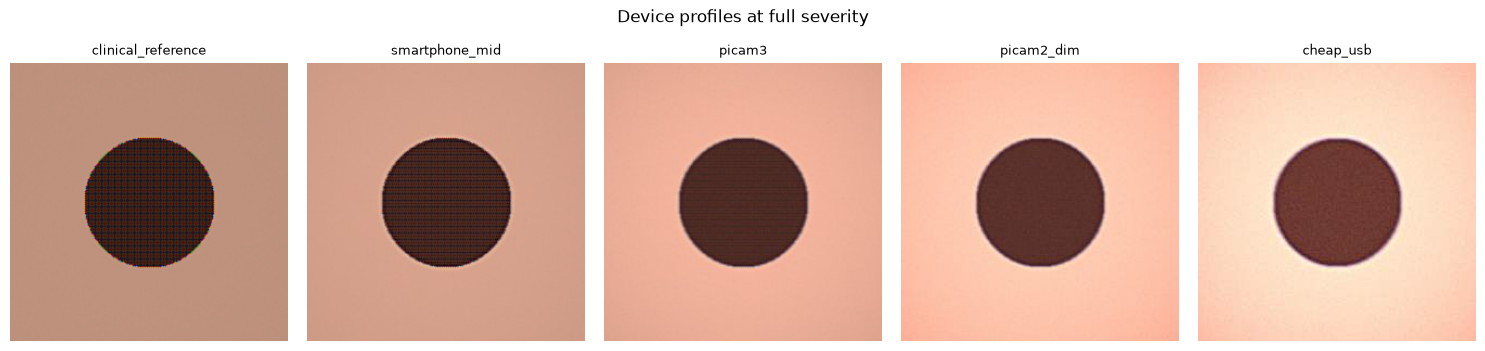

In [ ]:
fig, axes = plt.subplots(1, len(CFG.eval_cameras), figsize=(3 * len(CFG.eval_cameras), 3.4))
for ax, name in zip(np.atleast_1d(axes), CFG.eval_cameras):
    ax.imshow(simulate_capture(demo_img, PROFILES[name], rng=np.random.default_rng(11)))
    ax.set_title(name, fontsize=9); ax.axis("off")
plt.suptitle("Device profiles at full severity", y=1.02)
plt.tight_layout(); plt.show()

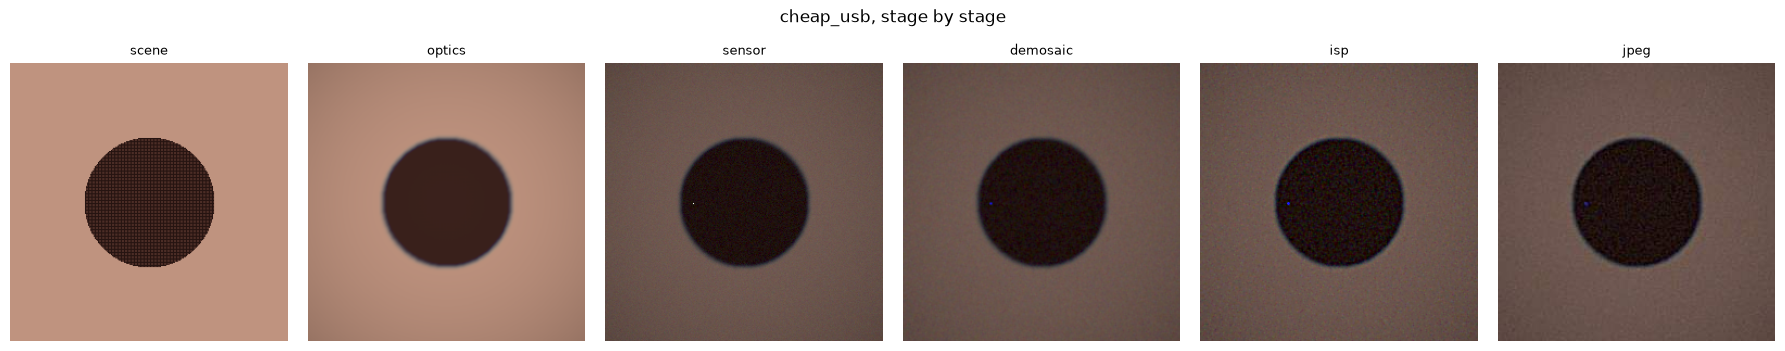

In [ ]:
# Stage-by-stage breakdown, useful for the write-up
_, stages = simulate_capture(demo_img, PROFILES["cheap_usb"],
                             rng=np.random.default_rng(5), return_stages=True)
fig, axes = plt.subplots(1, len(stages) + 1, figsize=(3 * (len(stages) + 1), 3.4))
axes[0].imshow(demo_img); axes[0].set_title("scene", fontsize=9); axes[0].axis("off")
for ax, (k, v) in zip(axes[1:], stages.items()):
    ax.imshow(v); ax.set_title(k, fontsize=9); ax.axis("off")
plt.suptitle("cheap_usb, stage by stage", y=1.02)
plt.tight_layout(); plt.show()

## 5. Embedding extraction and caching

The encoder is frozen, so re-encoding the same images every epoch is wasted GPU time.
Extract once per (benchmark, camera, severity) and cache to disk.

Degradation is applied to the **PIL image before `preprocess`**, which is the only
correct place for it — degrading after normalisation would be operating on tensors that
no longer represent pixel intensities.

Each image gets a deterministic seed derived from its path, so corruption is reproducible
across runs and identical between the linear probe and the trained head.

In [ ]:
def _stable_seed(*parts) -> int:
    h = hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest()
    return int(h[:8], 16)


@torch.no_grad()
def extract_embeddings(spec, df, camera=None, severity=0.0, cfg=CFG, use_cache=True):
    '''Encode a dataframe of images, optionally through a simulated camera.

    Returns a float32 tensor [N, EMBED_DIM] on CPU.
    '''
    tag = f"{spec.key}__{camera or 'clean'}__{severity:.2f}__{len(df)}"
    cache_path = Path(cfg.cache_dir) / f"{tag}.pt"
    if use_cache and cache_path.exists():
        return torch.load(cache_path)

    profile = None
    if camera is not None and severity > 0:
        profile = scale_profile(PROFILES[camera], severity)

    chunks = []
    for start in range(0, len(df), cfg.embed_batch_size):
        batch = df.iloc[start:start + cfg.embed_batch_size]
        tensors = []
        for _, row in batch.iterrows():
            img = Image.open(Path(spec.img_dir) / str(row["image_path"])).convert("RGB")
            if profile is not None:
                rng = np.random.default_rng(_stable_seed(row["image_path"], camera, severity))
                img = simulate_capture(img, profile, rng=rng)
            tensors.append(preprocess(img))
        px = torch.stack(tensors).to(DEVICE)
        feats = model.encode_image(px)
        feats = F.normalize(feats, dim=-1)   # CLIP features are used on the unit sphere
        chunks.append(feats.float().cpu())

    out = torch.cat(chunks, dim=0)
    if use_cache:
        torch.save(out, cache_path)
    return out


def embedding_plan(spec, df, cfg=CFG):
    '''Everything that needs encoding for one benchmark.'''
    plan = {"train": {}, "val": {}, "test": {}}
    tr = df[df.split == "train"]; va = df[df.split == "val"]; te = df[df.split == "test"]
    for s in cfg.train_severities:
        plan["train"][(cfg.train_camera, s)] = (tr, cfg.train_camera, s)
    plan["val"][("clean", 0.0)] = (va, None, 0.0)
    plan["test"][("clean", 0.0)] = (te, None, 0.0)
    for cam in cfg.eval_cameras:
        plan["test"][(cam, cfg.eval_severity)] = (te, cam, cfg.eval_severity)
    return plan


EMB = {}
for k in ACTIVE:
    spec, df = BENCHMARKS[k], DATA[k]
    print(f"\n[{spec.display}] extracting ...")
    EMB[k] = {}
    for split, jobs in embedding_plan(spec, df).items():
        EMB[k][split] = {}
        for key, (sub, cam, sev) in jobs.items():
            EMB[k][split][key] = extract_embeddings(spec, sub, cam, sev)
            print(f"   {split:6s} {str(key):32s} {tuple(EMB[k][split][key].shape)}")

if not ACTIVE:
    print("No benchmarks configured - nothing to extract.")

No benchmarks configured - nothing to extract.


## 6. Zero-shot baseline

DermLIP is a CLIP-style model, so it can classify by comparing an image embedding against
text prompt embeddings — **no training at all**. Two reasons to run this first:

1. It is an immediate end-to-end check that loading and preprocessing are correct.
2. It is a floor. If your trained probe does not beat zero-shot, something is wrong with
   the head, not the encoder.

Published zero-shot averages across these four benchmarks: DermLIP ViT-B/16 `.561`,
versus MONET `.400` and BiomedCLIP `.441`. Useful as a research baseline, nowhere near
deployable on its own.

Prompt wording moves these numbers noticeably, so treat the registered prompts as a
starting point rather than a tuned configuration.

In [ ]:
@torch.no_grad()
def zero_shot_logits(spec, embeddings):
    prompts = [spec.prompts[c] for c in spec.classes]
    toks = tokenizer(prompts).to(DEVICE)
    tfeat = F.normalize(model.encode_text(toks).float(), dim=-1).cpu()
    return embeddings @ tfeat.T          # both already L2-normalised


def multiclass_metrics(y_true, probs, classes):
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs)
    pred = probs.argmax(axis=1)
    present = np.unique(y_true)
    out = {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "n": len(y_true),
    }
    try:
        out["macro_auroc"] = roc_auc_score(
            y_true, probs, multi_class="ovr", average="macro", labels=np.arange(len(classes))
        ) if len(present) > 1 else np.nan
    except Exception:
        out["macro_auroc"] = np.nan
    return out


zs_rows = []
for k in ACTIVE:
    spec, df = BENCHMARKS[k], DATA[k]
    te = df[df.split == "test"]
    logits = zero_shot_logits(spec, EMB[k]["test"][("clean", 0.0)])
    probs = torch.softmax(logits * 100.0, dim=-1).numpy()
    m = multiclass_metrics(te["y"].values, probs, spec.classes)
    m.update({"benchmark": spec.display, "method": "zero-shot"})
    zs_rows.append(m)

zs_df = pd.DataFrame(zs_rows) if zs_rows else pd.DataFrame(
    [{"benchmark": BENCHMARKS[k].display, "method": "zero-shot", "accuracy": np.nan,
      "balanced_accuracy": np.nan, "macro_f1": np.nan, "macro_auroc": np.nan, "n": 0}
     for k in BENCHMARKS]
)
print(zs_df.to_string(index=False))

     benchmark    method  accuracy  balanced_accuracy  macro_f1  macro_auroc  n
      HAM10000 zero-shot       NaN                NaN       NaN          NaN  0
   PAD-UFES-20 zero-shot       NaN                NaN       NaN          NaN  0
Fitzpatrick17K zero-shot       NaN                NaN       NaN          NaN  0
      Daffodil zero-shot       NaN                NaN       NaN          NaN  0


## 7. Linear probe

Freeze the encoder, fit multinomial logistic regression on the embeddings. This is the
cleanest measure of the representation itself: *how separable are these classes when
DermLIP is untouched?*

This is also the number directly comparable to the published figures
(PAD `.761`, HAM `.852`, F17K `.510`, Daffodil `.964`).

Fitted on clean embeddings only. Section 9 evaluates it under corruption, which gives the
robustness baseline that the degradation-aware head in section 8 has to beat.

In [ ]:
def fit_linear_probe(spec, k, cfg=CFG):
    df = DATA[k]
    Xtr = EMB[k]["train"][(cfg.train_camera, 0.0)].numpy()
    ytr = df[df.split == "train"]["y"].values
    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
    )
    probe.fit(Xtr, ytr)
    return probe


PROBES = {}
lp_rows = []
for k in ACTIVE:
    spec, df = BENCHMARKS[k], DATA[k]
    PROBES[k] = fit_linear_probe(spec, k)
    te = df[df.split == "test"]
    probs = PROBES[k].predict_proba(EMB[k]["test"][("clean", 0.0)].numpy())
    m = multiclass_metrics(te["y"].values, probs, spec.classes)
    m.update({"benchmark": spec.display, "method": "linear probe (clean)"})
    lp_rows.append(m)

lp_df = pd.DataFrame(lp_rows) if lp_rows else pd.DataFrame(
    [{"benchmark": BENCHMARKS[k].display, "method": "linear probe (clean)",
      "accuracy": np.nan, "balanced_accuracy": np.nan, "macro_f1": np.nan,
      "macro_auroc": np.nan, "n": 0} for k in BENCHMARKS]
)
print(lp_df.to_string(index=False))

     benchmark               method  accuracy  balanced_accuracy  macro_f1  macro_auroc  n
      HAM10000 linear probe (clean)       NaN                NaN       NaN          NaN  0
   PAD-UFES-20 linear probe (clean)       NaN                NaN       NaN          NaN  0
Fitzpatrick17K linear probe (clean)       NaN                NaN       NaN          NaN  0
      Daffodil linear probe (clean)       NaN                NaN       NaN          NaN  0


## 8. Robustness-aware shared-adapter head

This keeps the shared-adapter design from the MedSigLIP notebook, generalised from binary
to multiclass. The architecture:

```
DermLIP embedding -> shared adapter -> classifier
                                    -> contrastive projector
```

The shared adapter is the important part. If the classifier and the contrastive projector
were separate branches off a frozen encoder, the InfoNCE loss would train a branch the
classifier never uses, and the robustness objective would have no effect on predictions.
Sharing the adapter means clean/degraded agreement actually shapes the features the
classifier reads. That was a good catch in the original notebook and it carries over
unchanged.

Training pairs each clean embedding with its degraded counterpart at a randomly chosen
severity, and optimises cross-entropy on both plus InfoNCE between them.

In [ ]:
class RobustHead(nn.Module):
    def __init__(self, embed_dim, n_classes, adapter_dim=256, proj_dim=128, dropout=0.2):
        super().__init__()
        self.adapter = nn.Sequential(
            nn.Linear(embed_dim, adapter_dim),
            nn.LayerNorm(adapter_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.classifier = nn.Linear(adapter_dim, n_classes)
        self.projector = nn.Sequential(
            nn.Linear(adapter_dim, proj_dim), nn.GELU(), nn.Linear(proj_dim, proj_dim),
        )

    def forward(self, emb):
        h = self.adapter(emb)
        return self.classifier(h), F.normalize(self.projector(h), dim=-1)


def info_nce(z1, z2, temperature=0.1):
    logits = z1 @ z2.T / temperature
    labels = torch.arange(z1.size(0), device=z1.device)
    return 0.5 * (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels))


def class_weights(y, n_classes):
    counts = np.bincount(np.asarray(y).astype(int), minlength=n_classes).astype(float)
    w = len(y) / (n_classes * np.maximum(counts, 1.0))
    return torch.tensor(w, dtype=torch.float32)


def train_head(k, cfg=CFG, verbose=True):
    spec, df = BENCHMARKS[k], DATA[k]
    tr = df[df.split == "train"]; va = df[df.split == "val"]
    ytr = torch.tensor(tr["y"].values, dtype=torch.long)
    yva = va["y"].values

    head = RobustHead(EMBED_DIM, spec.n_classes, cfg.adapter_dim,
                      cfg.proj_dim, cfg.dropout).to(DEVICE)
    ce = nn.CrossEntropyLoss(weight=class_weights(tr["y"].values, spec.n_classes).to(DEVICE))
    opt = torch.optim.AdamW(head.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)

    sev_options = [s for s in cfg.train_severities if s > 0] or [0.0]
    clean = EMB[k]["train"][(cfg.train_camera, 0.0)]
    Xva = EMB[k]["val"][("clean", 0.0)].to(DEVICE)

    best_state, best_score, history = None, -np.inf, []
    n = len(tr)
    for epoch in range(cfg.epochs):
        head.train()
        perm = torch.randperm(n)
        tot = 0.0; steps = 0
        for start in range(0, n, cfg.batch_size):
            idx = perm[start:start + cfg.batch_size]
            if len(idx) < 2:
                continue
            sev = random.choice(sev_options)
            e_clean = clean[idx].to(DEVICE)
            e_deg = EMB[k]["train"][(cfg.train_camera, sev)][idx].to(DEVICE)
            yb = ytr[idx].to(DEVICE)

            lc, pc = head(e_clean)
            ld, pd_ = head(e_deg)
            loss = 0.5 * (ce(lc, yb) + ce(ld, yb)) \
                   + cfg.contrastive_weight * info_nce(pc, pd_, cfg.contrastive_temperature)

            opt.zero_grad(set_to_none=True)
            loss.backward(); opt.step()
            tot += float(loss); steps += 1

        head.eval()
        with torch.no_grad():
            probs = torch.softmax(head(Xva)[0], dim=-1).cpu().numpy()
        score = balanced_accuracy_score(yva, probs.argmax(1))
        history.append({"epoch": epoch + 1, "loss": tot / max(steps, 1), "val_bacc": score})
        if score > best_score:
            best_score = score
            best_state = {kk: v.detach().clone() for kk, v in head.state_dict().items()}

    if best_state:
        head.load_state_dict(best_state)
    if verbose:
        print(f"[{spec.display}] best val balanced accuracy = {best_score:.4f}")
    return head, pd.DataFrame(history)


HEADS, HISTORY = {}, {}
for k in ACTIVE:
    HEADS[k], HISTORY[k] = train_head(k)

if not ACTIVE:
    print("No benchmarks configured - no heads trained.")

No benchmarks configured - no heads trained.


In [ ]:
if ACTIVE:
    fig, axes = plt.subplots(1, len(ACTIVE), figsize=(4.2 * len(ACTIVE), 3.2), squeeze=False)
    for ax, k in zip(axes[0], ACTIVE):
        h = HISTORY[k]
        ax.plot(h["epoch"], h["val_bacc"], marker="o", ms=3)
        ax.set_title(BENCHMARKS[k].display, fontsize=10)
        ax.set_xlabel("epoch"); ax.set_ylabel("val balanced acc"); ax.set_ylim(0, 1)
    plt.tight_layout(); plt.show()
else:
    print("Nothing to plot.")

Nothing to plot.


## 9. Evaluation: benchmarks x camera profiles

The main results table. Every benchmark, every device profile, both methods.

Report **balanced accuracy** as the headline. HAM10000 is roughly 67% `nv`, so plain
accuracy rewards a model that predicts the majority class and ignores melanoma.

**Retention** is performance under a given camera relative to the clean baseline. It is
the number that actually answers "will this survive on a Pi" — a model can have excellent
clean accuracy and terrible retention, and that combination is the one that looks fine in
a notebook and fails in a demo.

In [ ]:
def evaluate_all(cfg=CFG):
    rows = []
    for k in BENCHMARKS:
        spec = BENCHMARKS[k]
        if k not in ACTIVE:
            for cam in ("clean",) + tuple(cfg.eval_cameras):
                for method in ("linear probe", "robust head"):
                    rows.append({"benchmark": spec.display, "modality": spec.modality,
                                 "camera": cam, "method": method, "status": "NOT CONFIGURED",
                                 "accuracy": np.nan, "balanced_accuracy": np.nan,
                                 "macro_f1": np.nan, "macro_auroc": np.nan, "n": 0})
            continue

        df = DATA[k]; te = df[df.split == "test"]; y = te["y"].values
        for key, emb in EMB[k]["test"].items():
            cam = key[0]
            lp = PROBES[k].predict_proba(emb.numpy())
            with torch.no_grad():
                rh = torch.softmax(HEADS[k](emb.to(DEVICE))[0], dim=-1).cpu().numpy()
            for method, probs in (("linear probe", lp), ("robust head", rh)):
                m = multiclass_metrics(y, probs, spec.classes)
                m.update({"benchmark": spec.display, "modality": spec.modality,
                          "camera": cam, "method": method, "status": "READY"})
                rows.append(m)

    out = pd.DataFrame(rows)
    base = (out[out.camera == "clean"]
            .set_index(["benchmark", "method"])["balanced_accuracy"].to_dict())
    out["retention_%"] = [
        100 * r["balanced_accuracy"] / base[(r["benchmark"], r["method"])]
        if base.get((r["benchmark"], r["method"]), np.nan) not in (0, np.nan)
        and not pd.isna(base.get((r["benchmark"], r["method"]), np.nan)) else np.nan
        for _, r in out.iterrows()
    ]
    return out


RESULTS = evaluate_all()
cols = ["benchmark", "modality", "camera", "method", "status",
        "balanced_accuracy", "macro_auroc", "macro_f1", "retention_%", "n"]
print(RESULTS[cols].to_string(index=False))
RESULTS.to_csv(Path(CFG.output_dir) / "results.csv", index=False)

     benchmark              modality             camera       method         status  balanced_accuracy  macro_auroc  macro_f1  retention_%  n
      HAM10000            dermoscopy              clean linear probe NOT CONFIGURED                NaN          NaN       NaN          NaN  0
      HAM10000            dermoscopy              clean  robust head NOT CONFIGURED                NaN          NaN       NaN          NaN  0
      HAM10000            dermoscopy clinical_reference linear probe NOT CONFIGURED                NaN          NaN       NaN          NaN  0
      HAM10000            dermoscopy clinical_reference  robust head NOT CONFIGURED                NaN          NaN       NaN          NaN  0
      HAM10000            dermoscopy     smartphone_mid linear probe NOT CONFIGURED                NaN          NaN       NaN          NaN  0
      HAM10000            dermoscopy     smartphone_mid  robust head NOT CONFIGURED                NaN          NaN       NaN          NaN  0
      

In [ ]:
piv = RESULTS[RESULTS.status == "READY"]
if len(piv):
    for method in ("linear probe", "robust head"):
        sub = piv[piv.method == method].pivot_table(
            index="camera", columns="benchmark", values="balanced_accuracy")
        order = [c for c in ("clean",) + tuple(CFG.eval_cameras) if c in sub.index]
        print(f"\n=== {method}: balanced accuracy ===")
        print(sub.reindex(order).round(4).to_string())
else:
    print("No configured benchmarks - the table above is the schema, populated with NaN.")
    print("Wire up at least PAD-UFES-20 to get real numbers.")

No configured benchmarks - the table above is the schema, populated with NaN.
Wire up at least PAD-UFES-20 to get real numbers.


In [ ]:
if len(piv):
    order = [c for c in ("clean",) + tuple(CFG.eval_cameras)]
    fig, axes = plt.subplots(1, len(ACTIVE), figsize=(4.6 * len(ACTIVE), 3.6), squeeze=False)
    for ax, k in zip(axes[0], ACTIVE):
        d = piv[piv.benchmark == BENCHMARKS[k].display]
        for method in ("linear probe", "robust head"):
            s = d[d.method == method].set_index("camera")["retention_%"].reindex(order)
            ax.plot(range(len(order)), s.values, marker="o", label=method)
        ax.axhline(100, ls="--", lw=1, c="grey")
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order, rotation=40, ha="right", fontsize=8)
        ax.set_ylabel("retention vs clean (%)"); ax.set_ylim(0, 115)
        ax.set_title(BENCHMARKS[k].display, fontsize=10); ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(Path(CFG.output_dir) / "retention.png", dpi=160)
    plt.show()
else:
    print("Nothing to plot until a benchmark is configured.")

Nothing to plot until a benchmark is configured.


### Triage view

For the benchmarks with malignant classes, collapse to malignant-vs-rest and pick the
threshold on **validation** data targeting 90% sensitivity. This preserves the
triage framing from the MedSigLIP notebook, where a false negative costs far more than a
false positive.

The 90% target is an experimental choice here, not a clinical recommendation.

In [ ]:
def triage_view(k, cfg=CFG):
    spec, df = BENCHMARKS[k], DATA[k]
    if not spec.malignant:
        return None
    mal_idx = [spec.classes.index(c) for c in spec.malignant]

    def mal_prob(probs):
        return probs[:, mal_idx].sum(axis=1)

    va = df[df.split == "val"]; te = df[df.split == "test"]
    with torch.no_grad():
        pv = torch.softmax(HEADS[k](EMB[k]["val"][("clean", 0.0)].to(DEVICE))[0], -1).cpu().numpy()
    yv = np.isin(va["y"].values, mal_idx).astype(int)
    sv = mal_prob(pv)

    best = (0.5, 0.0, 0.0)
    for t in np.unique(np.concatenate([[0.0], sv, [1.0]])):
        pred = (sv >= t).astype(int)
        sens = recall_score(yv, pred, pos_label=1, zero_division=0)
        spec_ = recall_score(yv, pred, pos_label=0, zero_division=0)
        if sens >= cfg.target_validation_sensitivity and spec_ > best[2]:
            best = (float(t), float(sens), float(spec_))
    thr = best[0]

    rows = []
    yt = np.isin(te["y"].values, mal_idx).astype(int)
    for key, emb in EMB[k]["test"].items():
        with torch.no_grad():
            p = torch.softmax(HEADS[k](emb.to(DEVICE))[0], -1).cpu().numpy()
        s = mal_prob(p); pred = (s >= thr).astype(int)
        rows.append({
            "benchmark": spec.display, "camera": key[0], "threshold": thr,
            "sensitivity": recall_score(yt, pred, pos_label=1, zero_division=0),
            "specificity": recall_score(yt, pred, pos_label=0, zero_division=0),
            "auroc": roc_auc_score(yt, s) if len(np.unique(yt)) > 1 else np.nan,
            "auprc": average_precision_score(yt, s) if len(np.unique(yt)) > 1 else np.nan,
        })
    return pd.DataFrame(rows)


triage = [t for t in (triage_view(k) for k in ACTIVE) if t is not None]
if triage:
    TRIAGE = pd.concat(triage, ignore_index=True)
    base = TRIAGE[TRIAGE.camera == "clean"].set_index("benchmark")["sensitivity"].to_dict()
    TRIAGE["sens_retained_%"] = [100 * r.sensitivity / base[r.benchmark]
                                 if base.get(r.benchmark) else np.nan
                                 for r in TRIAGE.itertuples()]
    print(TRIAGE.round(4).to_string(index=False))
    TRIAGE.to_csv(Path(CFG.output_dir) / "triage.csv", index=False)
else:
    print("No configured benchmark with malignant classes - triage view unavailable.")

No configured benchmark with malignant classes - triage view unavailable.


In [ ]:
# Subgroup analysis - only meaningful on Fitzpatrick17K, which carries skin type.
def subgroup_table(k, group_col="fitzpatrick"):
    spec, df = BENCHMARKS[k], DATA[k]
    te = df[df.split == "test"]
    if group_col not in te.columns:
        return None
    with torch.no_grad():
        p = torch.softmax(HEADS[k](EMB[k]["test"][("clean", 0.0)].to(DEVICE))[0], -1).cpu().numpy()
    pred = p.argmax(1); work = te.copy(); work["_pred"] = pred
    rows = []
    for g, sub in work.groupby(group_col):
        rows.append({group_col: g, "n": len(sub),
                     "balanced_accuracy": balanced_accuracy_score(sub["y"], sub["_pred"]),
                     "accuracy": accuracy_score(sub["y"], sub["_pred"])})
    return pd.DataFrame(rows)


any_sub = False
for k in ACTIVE:
    t = subgroup_table(k)
    if t is not None:
        any_sub = True
        print(f"\n=== {BENCHMARKS[k].display} by Fitzpatrick type ===")
        print(t.round(4).to_string(index=False))
        print("Small groups give unstable estimates - read n before reading the score.")
if not any_sub:
    print("No 'fitzpatrick' column in any configured benchmark - skipping subgroup analysis.")
    print("This is the check that catches skin-tone performance gaps. Do not skip it for real.")

No 'fitzpatrick' column in any configured benchmark - skipping subgroup analysis.
This is the check that catches skin-tone performance gaps. Do not skip it for real.


## 10. Validating the simulator against real device photos

Everything in section 9 rests on an assumption: that `simulate_capture` produces images
that resemble what the real target camera produces. Nothing so far has tested that. A
simulator can be internally consistent, monotonic, and physically motivated, and still be
a poor match for the actual device.

This is the difference between "we simulated degradation" and "we validated our
degradation model", and it is cheap to do — perhaps an afternoon with the Pi.

**Procedure**

1. Photograph 30–50 targets with **both** the reference setup and the Pi camera, in the
   same session, same lighting, same distance. Printed lesion images work; real skin is
   better if you have consent.
2. Run the reference images through `simulate_capture` at several profiles and severities.
3. Encode all three sets with DermLIP.
4. Compare the *simulated* distribution to the *real Pi* distribution in embedding space.

If the best-matching profile sits well away from `picam3`, recalibrate the profile
parameters until it lands there. If nothing matches well, the simulator is missing an
effect the real device has.

The helper below reports mean embedding distance and a simple Frechet distance. Neither
is a perfect metric, but a clear minimum at the profile you expect is good evidence.

In [ ]:
def frechet_distance(A, B, eps=1e-6):
    '''Frechet distance between two Gaussians fitted to embedding sets.

    Same construction as FID, computed on DermLIP embeddings instead of Inception.
    '''
    A = np.asarray(A, dtype=np.float64); B = np.asarray(B, dtype=np.float64)
    mu1, mu2 = A.mean(0), B.mean(0)
    s1 = np.cov(A, rowvar=False) + eps * np.eye(A.shape[1])
    s2 = np.cov(B, rowvar=False) + eps * np.eye(B.shape[1])
    # sqrtm via eigendecomposition of the symmetric product
    w, v = np.linalg.eigh(s1)
    s1_half = v @ np.diag(np.sqrt(np.clip(w, 0, None))) @ v.T
    w2, v2 = np.linalg.eigh(s1_half @ s2 @ s1_half)
    tr_cov = np.sum(np.sqrt(np.clip(w2, 0, None)))
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr_cov)


@torch.no_grad()
def encode_paths(paths, camera=None, severity=1.0, batch=32):
    profile = scale_profile(PROFILES[camera], severity) if camera else None
    chunks = []
    for i in range(0, len(paths), batch):
        tens = []
        for p in paths[i:i + batch]:
            img = Image.open(p).convert("RGB")
            if profile is not None:
                img = simulate_capture(img, profile, rng=np.random.default_rng(_stable_seed(p, camera, severity)))
            tens.append(preprocess(img))
        f = model.encode_image(torch.stack(tens).to(DEVICE))
        chunks.append(F.normalize(f, dim=-1).float().cpu())
    return torch.cat(chunks).numpy()


def calibrate_simulator(reference_dir, real_device_dir, cameras=None, severities=(0.5, 0.75, 1.0)):
    ref = sorted(str(p) for p in Path(reference_dir).glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    real = sorted(str(p) for p in Path(real_device_dir).glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    if not ref or not real:
        print("Provide two folders: reference captures and real target-device captures.")
        return None
    cameras = cameras or list(PROFILES.keys())
    E_real = encode_paths(real)
    rows = [{"camera": "reference (undegraded)", "severity": 0.0,
             "frechet": frechet_distance(encode_paths(ref), E_real)}]
    for cam in cameras:
        for s in severities:
            rows.append({"camera": cam, "severity": s,
                         "frechet": frechet_distance(encode_paths(ref, cam, s), E_real)})
    out = pd.DataFrame(rows).sort_values("frechet").reset_index(drop=True)
    print(out.round(4).to_string(index=False))
    print(f"\nBest match: {out.iloc[0]['camera']} @ severity {out.iloc[0]['severity']}")
    print("If that is not the profile you expected, retune the profile parameters.")
    return out


# calibrate_simulator("data/calib/reference", "data/calib/picam")
print("Uncomment the last line once you have paired captures. See the markdown above.")

Uncomment the last line once you have paired captures. See the markdown above.


## 11. Export

Saves the trained heads, the fitted probes, the locked thresholds, and the full config
(including every camera profile, so the degradation is reproducible later).

This does **not** make DermLIP Pi-sized. The head is a few hundred KB; the ViT-B/16 vision
tower is ~86M parameters.

In [ ]:
artifact = {
    "model_id": CFG.model_id,
    "embed_dim": EMBED_DIM,
    "config": asdict(CFG) if hasattr(CFG, "__dataclass_fields__") else CFG.__dict__,
    "camera_profiles": {k: asdict(v) for k, v in PROFILES.items()},
    "benchmarks": {k: {"classes": b.classes, "modality": b.modality} for k, b in BENCHMARKS.items()},
    "heads": {k: HEADS[k].state_dict() for k in ACTIVE},
}
out_path = Path(CFG.output_dir) / "dermlip_heads.pt"
torch.save(artifact, out_path)

import pickle
if PROBES:
    with open(Path(CFG.output_dir) / "linear_probes.pkl", "wb") as f:
        pickle.dump(PROBES, f)

print("Saved:", out_path)
for p in sorted(Path(CFG.output_dir).glob("*")):
    print("  ", p)

Saved: outputs_dermlip\dermlip_heads.pt
   outputs_dermlip\dermlip_heads.pt
   outputs_dermlip\results.csv


## Next steps

**Before any result is trustworthy**

1. Wire up PAD-UFES-20 first — it is the closest proxy to the deployment camera. Use the
   pre-split version from the Derm1M or PanDerm repos so your numbers are comparable to
   the papers.
2. Confirm `patient_id` is present and that splitting is grouped. Lesion-level leakage is
   the most common way a dermatology pipeline reports a number it cannot reproduce.
3. Run section 10. An unvalidated degradation model is a guess with error bars you cannot
   see.

**Decisions still open**

- **Dermatoscope or bare camera?** This determines whether HAM10000 is relevant training
  data at all. A ~$30 clip-on lens keeps you in the dermoscopy domain and makes the
  strongest public datasets usable. Decide before collecting data.
- **Which AI HAT?** The original (Hailo-8) cannot compile CLIP ViT-L/14 at all, and
  ViT-B/16 will likely need multiple contexts. The AI HAT+ 2 (Hailo-10H, 8GB) changes
  that. This is the difference between deploying DermLIP directly and needing to distil
  into a MobileNet student.
- **Licence.** Resolve the `cc-by-4.0` vs `cc-by-nc-nd-4.0` contradiction before anything
  ships.

**If you do need distillation**, the path is: train this head -> generate soft targets on
your data -> train MobileNetV3 or EfficientNet-B0 against labels plus soft targets ->
quantise INT8 -> compile. Calibration data for quantisation must come from your real
capture setup, not from HAM10000, or you compound the domain gap with a quantisation gap.